# Deep Learning — Exercise Sheet 01
Winter Term 2026/2027

**Name(s):**<br>
Elena Waelsch<br>
Annabell Blaumann<br>
Natalia Maczynska

## 1. Derivatives

##### (a) **Task:**
Let $\sigma(x)=\frac{1}{1+e^{-x}}$, $\sigma:\mathbb{R}\to\mathbb{R}$. Show that $\sigma'(x)=\sigma(x)(1-\sigma(x))$
<br><br>

**Answer:** Rewrite the sigmoid as
$$
\sigma(x)=(1+e^{-x})^{-1}.
$$

Using the chain rule:
$$
\sigma'(x)
=-(1+e^{-x})^{-2}\cdot(-e^{-x})
=\frac{e^{-x}}{(1+e^{-x})^2}.
$$

Since:
$$
1-\sigma(x)=1-\frac{1}{1+e^{-x}}=\frac{e^{-x}}{1+e^{-x}},
$$

we obtain:
$$
\boxed{
\sigma'(x)
=\frac{1}{1+e^{-x}}\cdot\frac{e^{-x}}{1+e^{-x}}
=\sigma(x)(1-\sigma(x)).
}
$$

##### (b) **Task:**
Let $f(x)=\sin\bigl(\ln(x^Tx)\bigr)$, $f:\mathbb{R}^n\to\mathbb{R}$. Compute the gradient $\nabla_x f(x)$ and state its dimension.
<br><br>

**Answer:** First, write the inner expression as:
$$
u(x)=x^Tx=\sum_{i=1}^{n}x_i^2.
$$

For each component $x_j$:
$$
\frac{\partial u}{\partial x_j}=2x_j.
$$
Therefore:
$$
\nabla_x u=
\begin{pmatrix}
2x_1\\
\vdots\\
2x_n
\end{pmatrix}
=2x.
$$

Now introduce $v=\ln(u)$, so that $f=\sin(v)$. Their derivatives are:
$$
\frac{dv}{du}=\frac{1}{u},
\qquad
\frac{df}{dv}=\cos(v).
$$

Applying the chain rule:
$$
\nabla_x f
=\frac{df}{dv}\cdot\frac{dv}{du}\cdot\nabla_x u
=\cos(v)\cdot\frac{1}{u}\cdot2x.
$$

Substituting $u=x^Tx$ and $v=\ln(x^Tx)$:
$$
\boxed{
\nabla_x f(x)=\frac{2\cos(\ln(x^Tx))}{x^Tx}\,x
}
$$

The gradient contains one partial derivative for each of the $n$
input components. Using the column-vector convention, its dimension is:
$$
\boxed{\nabla_x f(x)\in\mathbb R^{n\times1}.}
$$

The function is defined only for $x\ne0$, because the logarithm
requires $x^Tx=\sum_{i=1}^{n}x_i^2>0$.

##### (c) **Task:**
Let $f(x)=\left(\sqrt{x_1^2-x_3},\,e^{x_2}\cos(4x_3)\right)^T$, $f:\mathbb{R}^3\to\mathbb{R}^2$. Compute the Jacobian matrix $\frac{\partial f(x)}{\partial x}$.
<br><br>

**Answer:** The function has three inputs and two outputs:
$$
f_1(x)=\sqrt{x_1^2-x_3},
\qquad
f_2(x)=e^{x_2}\cos(4x_3).
$$

The Jacobian contains one row per output and one column per input:
$$
J_f(x)=
\begin{pmatrix}
\frac{\partial f_1}{\partial x_1} &
\frac{\partial f_1}{\partial x_2} &
\frac{\partial f_1}{\partial x_3}\\
\frac{\partial f_2}{\partial x_1} &
\frac{\partial f_2}{\partial x_2} &
\frac{\partial f_2}{\partial x_3}
\end{pmatrix}.
$$
<br><br>
**First row:** For $f_1(x)$, set $u=x_1^2-x_3$. Since:
$$
\frac{d\sqrt{u}}{du}=\frac{1}{2\sqrt{u}},
$$

the chain rule gives:
$$
\frac{\partial f_1}{\partial x_1}
=\frac{1}{2\sqrt{x_1^2-x_3}}\cdot2x_1
=\frac{x_1}{\sqrt{x_1^2-x_3}}.
$$

The function $f_1$ does not depend on $x_2$, so:
$$
\frac{\partial f_1}{\partial x_2}=0.
$$

For $x_3$, the derivative of the inner expression is $-1$:
$$
\frac{\partial f_1}{\partial x_3}
=\frac{1}{2\sqrt{x_1^2-x_3}}\cdot(-1)
=-\frac{1}{2\sqrt{x_1^2-x_3}}.
$$
<br><br>
**Second row:** For $f_2(x)$,
there is no dependence on $x_1$, so:
$$
\frac{\partial f_2}{\partial x_1}=0.
$$

When differentiating with respect to $x_2$, the factor
$\cos(4x_3)$ is constant:
$$
\frac{\partial f_2}{\partial x_2}
=e^{x_2}\cos(4x_3).
$$

When differentiating with respect to $x_3$, the factor
$e^{x_2}$ is constant. Applying the chain rule to the cosine:
$$
\frac{\partial f_2}{\partial x_3}
=e^{x_2}\bigl(-\sin(4x_3)\bigr)\cdot4
=-4e^{x_2}\sin(4x_3).
$$

Combining all six partial derivatives:
$$
\boxed{
J_f(x)=
\begin{pmatrix}
\dfrac{x_1}{\sqrt{x_1^2-x_3}} & 0 &
-\dfrac{1}{2\sqrt{x_1^2-x_3}}\\
0 & e^{x_2}\cos(4x_3) & -4e^{x_2}\sin(4x_3)
\end{pmatrix}
}
$$

The Jacobian has dimension $2\times3$.
The formula is valid for $x_1^2-x_3>0$.

##### (d)
**Task:** Let $a:\mathbb{R}\to\mathbb{R}$ be differentiable and $f(x)=(a(x_1),\ldots,a(x_n))^T$, $f:\mathbb{R}^n\to\mathbb{R}^n$. Compute the Jacobian matrix $\frac{\partial f(x)}{\partial x}$. What is the characteristic feature of the resulting matrix?
<br><br>

**Answer:** Each output component is:
$$
f_i(x)=a(x_i).
$$

The entry in row $i$ and column $j$ of the Jacobian is:
$$
(J_f)_{ij}=\frac{\partial f_i}{\partial x_j}.
$$

If $i=j$, we differentiate $a(x_i)$ with respect to its own argument:
$$
\frac{\partial f_i}{\partial x_i}=a'(x_i).
$$

If $i\ne j$, the output $f_i=a(x_i)$ does not depend on $x_j$, so:
$$
\frac{\partial f_i}{\partial x_j}=0.
$$

Therefore:
$$
\frac{\partial f_i}{\partial x_j}
=
\begin{cases}
a'(x_i), & i=j,\\
0, & i\ne j.
\end{cases}
$$

Combining these entries:
$$
\boxed{
J_f(x)=
\begin{pmatrix}
a'(x_1) & 0 & \cdots & 0\\
0 & a'(x_2) & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & a'(x_n)
\end{pmatrix}
=\operatorname{diag}\bigl(a'(x_1),\ldots,a'(x_n)\bigr)
}
$$

The Jacobian has dimension $n\times n$.

Its characteristic feature is that it is **diagonal**:
each output depends only on the corresponding input, so all
off-diagonal entries are zero.

##### (e)
**Task:** Let $f(y)=\sin(y)$ and $y=Ax+b$, where $A\in\mathbb{R}^{M\times N}$, $x\in\mathbb{R}^N$, $b\in\mathbb{R}^M$, and $\sin(\cdot)$ is applied element-wise. Compute the Jacobian $\frac{df}{dx}$ using the chain rule and state its dimension. Hint: Your solution in (d) might be helpful here.
<br><br>

**Answer:** The computation consists of two steps:
$$
x\longmapsto y=Ax+b\longmapsto f(y)=\sin(y).
$$

First, each component of $y$ is:
$$
y_i=\sum_{j=1}^{N}A_{ij}x_j+b_i.
$$

Since $A$ and $b$ are constant with respect to $x$,
$$
\frac{\partial y_i}{\partial x_j}=A_{ij}.
$$
Therefore:
$$
\frac{\partial y}{\partial x}=A
\in\mathbb R^{M\times N}.
$$

Next, the sine function is applied separately to each component:
$$
f_i(y)=\sin(y_i).
$$

Using the result from part (d),
$$
\frac{\partial f_i}{\partial y_k}
=
\begin{cases}
\cos(y_i), & i=k,\\
0, & i\ne k.
\end{cases}
$$

Thus:
$$
\frac{\partial f}{\partial y}
=
\begin{pmatrix}
\cos(y_1) & 0 & \cdots & 0\\
0 & \cos(y_2) & \cdots & 0\\
\vdots & \vdots & \ddots & \vdots\\
0 & 0 & \cdots & \cos(y_M)
\end{pmatrix}
=\operatorname{diag}(\cos(y))
\in\mathbb R^{M\times M}.
$$

Applying the chain rule:
$$
\frac{df}{dx}
=\frac{\partial f}{\partial y}\frac{\partial y}{\partial x}
=\operatorname{diag}(\cos(y))A.
$$

Substituting $y=Ax+b$ gives:
$$
\boxed{
\frac{df}{dx}=\operatorname{diag}(\cos(Ax+b))A
}
$$

The dimensions of the matrix product are:
$$
(M\times M)(M\times N)=M\times N.
$$

Therefore, the Jacobian has dimension $M\times N$:
one row for each output and one column for each input.

## 2. Computational Graph and Backpropagation

Consider the following equation:
$$
\mathcal A=\sqrt{a+b+c^2}+\ln(a+b+c^2)+\frac{a+b+c^2}{bc^2}
$$

##### (a)
**Task:** Introduce intermediate variables $(t_1,t_2,t_3,\ldots)$ such that each assignment contains a single unary or binary operation. Reuse intermediate variables whenever possible.
<br><br>

**Answer:** First, compute the square and the sum:
$$
t_1=c^2,\qquad t_2=a+b.
$$
Combine them to obtain the expression shared by all three terms:
$$
t_3=t_2+t_1.
$$
Thus, $t_3=a+b+c^2$.

Compute the square root and the natural logarithm:
$$
t_4=\sqrt{t_3},\qquad t_5=\ln(t_3).
$$
Reuse $t_1=c^2$ to calculate the denominator, then divide:
$$
t_6=bt_1,\qquad t_7=\frac{t_3}{t_6}.
$$
Finally, add the three terms using two binary additions:
$$
t_8=t_4+t_5,\qquad \boxed{\mathcal A=t_8+t_7}.
$$
Each assignment contains exactly one operation. The intermediate results $t_1$ and $t_3$ are computed once and reused.

##### (b)
**Task:** Draw the computational graph (forward pass) based on the variables introduced in (a).
<br><br>

**Answer:** Each intermediate node represents the result of one operation. Arrows point from its inputs to its result. The labels show both the operation from part (a) and the expanded expression.

The orange nodes ($b$, $t_1$, $t_3$) receive multiple gradient contributions during the backward pass, as explained in part (c).

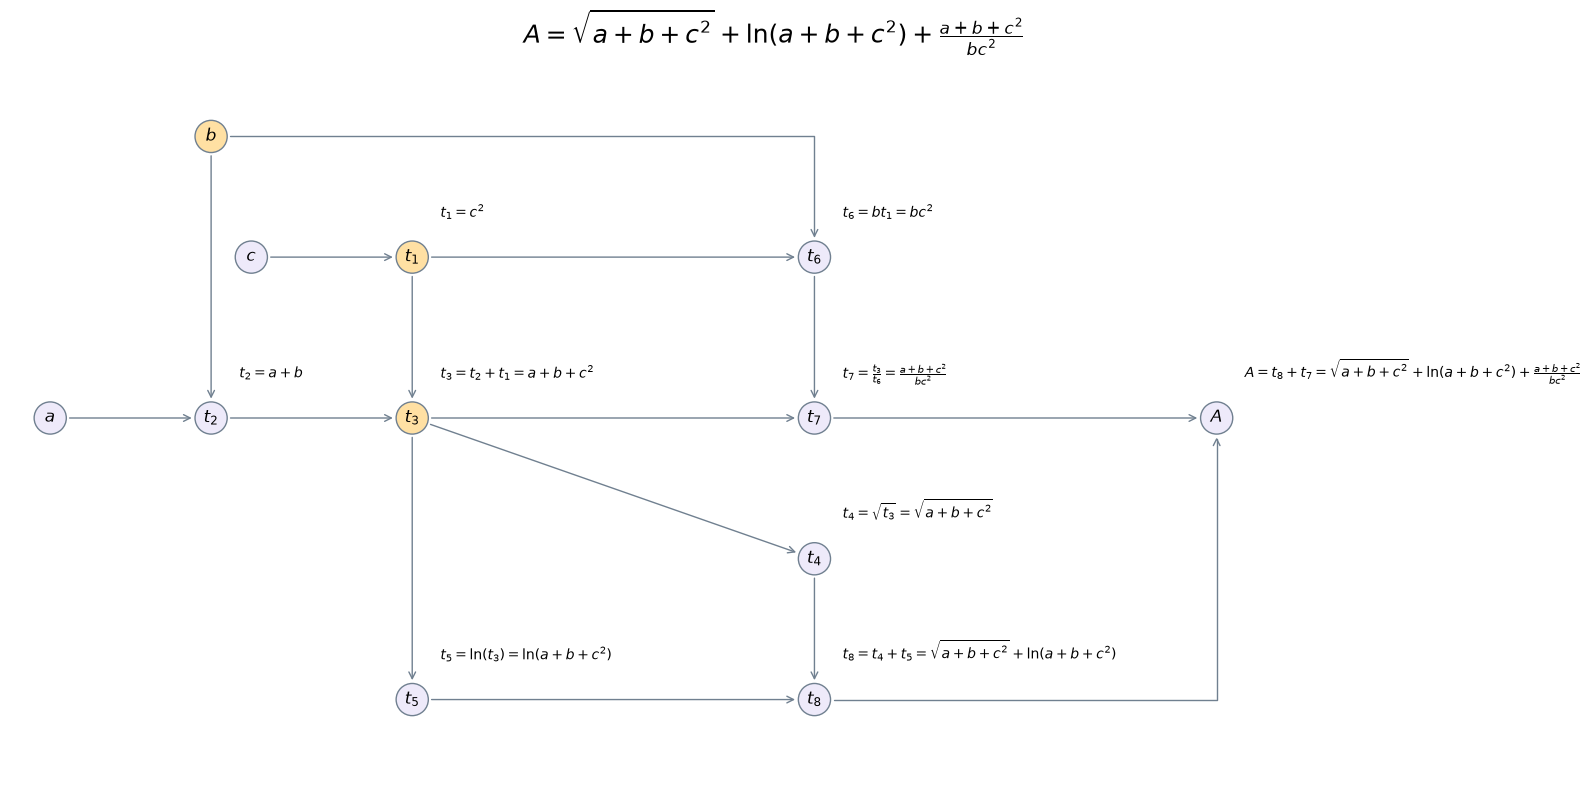

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(20, 8))
ax.set(xlim=(-10, 370), ylim=(-90, 90), aspect="equal")
ax.axis("off")

s = "a+b+c^2"
root, log = rf"\sqrt{{{s}}}", rf"\ln({s})"
fraction = rf"\frac{{{s}}}{{bc^2}}"

nodes = {
    "a": (0, 0, ""),
    "b": (40, 70, ""),
    "c": (50, 40, ""),
    "t_1": (90, 40, "c^2"),
    "t_2": (40, 0, "a+b"),
    "t_3": (90, 0, f"t_2+t_1={s}"),
    "t_4": (190, -35, rf"\sqrt{{t_3}}={root}"),
    "t_5": (90, -70, rf"\ln(t_3)={log}"),
    "t_6": (190, 40, "bt_1=bc^2"),
    "t_7": (190, 0, rf"\frac{{t_3}}{{t_6}}={fraction}"),
    "t_8": (190, -70, f"t_4+t_5={root}+{log}"),
    "A": (290, 0, f"t_8+t_7={root}+{log}+{fraction}")
}

circles = {}
for name, (x, y, formula) in nodes.items():
    color = "#ffe0a3" if name in {"b", "t_1", "t_3"} else "#eeeafa"
    circles[name] = Circle((x, y), 4, fc=color, ec="slategray")
    ax.add_patch(circles[name])
    ax.text(x, y, f"${name}$", ha="center", va="center", fontsize=12)
    if formula:
        ax.text(x + 7, y + 10, f"${name}={formula}$", fontsize=10)


def arrow(start, end, bent=False):
    ax.add_patch(FancyArrowPatch(
        nodes[start][:2], nodes[end][:2],
        patchA=circles[start], patchB=circles[end],
        connectionstyle="angle,angleA=0,angleB=90" if bent else "arc3",
        arrowstyle="->", mutation_scale=12, color="slategray"
    ))


for start, end in [
    ("a", "t_2"), ("b", "t_2"), ("c", "t_1"),
    ("t_1", "t_3"), ("t_2", "t_3"), ("t_1", "t_6"),
    ("t_3", "t_4"), ("t_3", "t_5"), ("t_3", "t_7"),
    ("t_6", "t_7"), ("t_4", "t_8"), ("t_5", "t_8"),
    ("t_7", "A")
]:
    arrow(start, end)

arrow("b", "t_6", bent=True)
arrow("t_8", "A", bent=True)

ax.set_title(f"$A={root}+{log}+{fraction}$", fontsize=18)
plt.tight_layout()
plt.show()

##### (c)
**Task:** For every node $v$ in the graph, write down the gradient $\frac{\partial\mathcal A}{\partial v}$ in terms of the gradients of the nodes that $v$ feeds into. You do not need to evaluate the partial derivatives between neighbouring nodes. Mark all nodes in your graph that receive more than one gradient signal.
<br><br>

**Answer:** Write
$$
g_v=\frac{\partial\mathcal A}{\partial v}.
$$
By the chain rule, each node receives a contribution from every operation that uses its value. These contributions are added:
$$
g_v=\sum_{u:\,v\to u}g_u\frac{\partial u}{\partial v}.
$$
Each local derivative treats the operation's other inputs as constant.

Start at the output:
$$
g_{\mathcal A}=1.
$$
Since $\mathcal A=t_8+t_7$:
$$
g_{t_8}=g_{\mathcal A}\frac{\partial\mathcal A}{\partial t_8},\qquad
g_{t_7}=g_{\mathcal A}\frac{\partial\mathcal A}{\partial t_7}.
$$
Since $t_8=t_4+t_5$:
$$
g_{t_4}=g_{t_8}\frac{\partial t_8}{\partial t_4},\qquad
g_{t_5}=g_{t_8}\frac{\partial t_8}{\partial t_5}.
$$
The node $t_6$ is used in $t_7=t_3/t_6$:
$$
g_{t_6}=g_{t_7}\frac{\partial t_7}{\partial t_6}.
$$
The node $t_3$ is used in $t_4$, $t_5$ and $t_7$:
$$
\boxed{g_{t_3}=g_{t_4}\frac{\partial t_4}{\partial t_3}
+g_{t_5}\frac{\partial t_5}{\partial t_3}
+g_{t_7}\frac{\partial t_7}{\partial t_3}}.
$$
The node $t_2$ is used in $t_3=t_2+t_1$:
$$
g_{t_2}=g_{t_3}\frac{\partial t_3}{\partial t_2}.
$$
The node $t_1$ is used in both $t_3$ and $t_6$:
$$
\boxed{g_{t_1}=g_{t_3}\frac{\partial t_3}{\partial t_1}
+g_{t_6}\frac{\partial t_6}{\partial t_1}}.
$$
Finally, the input gradients are:
$$
g_a=g_{t_2}\frac{\partial t_2}{\partial a},
$$
$$
\boxed{g_b=g_{t_2}\frac{\partial t_2}{\partial b}
+g_{t_6}\frac{\partial t_6}{\partial b}},
$$
$$
g_c=g_{t_1}\frac{\partial t_1}{\partial c}.
$$

The nodes receiving multiple gradient signals are:
- $t_3$: three contributions, from $t_4$, $t_5$ and $t_7$.
- $t_1$: two contributions, from $t_3$ and $t_6$.
- $b$: two contributions, from $t_2$ and $t_6$.

These nodes are marked in orange in the graph in part (b).

##### (d)
**Task:** Let $a=1$, $b=2$, $c=1$. Compute the value (forward pass) and the gradient $\frac{\partial\mathcal A}{\partial v}$ (backward pass) of every node $v$.
<br><br>

**Answer:**

**Forward pass:** Evaluate the operations from part (a):
$$
\begin{aligned}
t_1&=c^2=1,\\
t_2&=a+b=3,\\
t_3&=t_2+t_1=4,\\
t_4&=\sqrt{t_3}=2,\\
t_5&=\ln(t_3)=\ln4,\\
t_6&=bt_1=2,\\
t_7&=t_3/t_6=2,\\
t_8&=t_4+t_5=2+\ln4.
\end{aligned}
$$
Therefore,
$$
\boxed{\mathcal A=t_8+t_7=4+\ln4\approx5.386294.}
$$

**Backward pass:** Start with $g_{\mathcal A}=1$.
The additions $\mathcal A=t_8+t_7$ and $t_8=t_4+t_5$ have local derivatives equal to $1$. Thus,
$$
g_{t_8}=g_{t_7}=g_{t_4}=g_{t_5}=1.
$$
For the denominator $t_6$, use $t_7=t_3/t_6$:
$$
g_{t_6}=g_{t_7}\left(-\frac{t_3}{t_6^2}\right)
=1\left(-\frac{4}{2^2}\right)=-1.
$$
The node $t_3$ receives contributions from the square root, logarithm and division:
$$
\begin{aligned}
g_{t_3}&=g_{t_4}\frac{1}{2\sqrt{t_3}}+g_{t_5}\frac{1}{t_3}+g_{t_7}\frac{1}{t_6}\\
&=\frac14+\frac14+\frac12=1.
\end{aligned}
$$
Since $t_3=t_2+t_1$,
$$
g_{t_2}=g_{t_3}\cdot1=1.
$$
The node $t_1$ contributes through both $t_3=t_2+t_1$ and $t_6=bt_1$:
$$
g_{t_1}=g_{t_3}\cdot1+g_{t_6}\cdot b=1+(-1)\cdot2=-1.
$$
For the inputs:
$$
g_a=g_{t_2}\cdot1=1,
$$
$$
g_b=g_{t_2}\cdot1+g_{t_6}\cdot t_1=1+(-1)\cdot1=0,
$$
$$
g_c=g_{t_1}\cdot2c=(-1)\cdot2\cdot1=-2.
$$

**Results:**

| Node $v$ | Value | Gradient $g_v$ |
|---|---:|---:|
| $a$ | $1$ | $1$ |
| $b$ | $2$ | $0$ |
| $c$ | $1$ | $-2$ |
| $t_1$ | $1$ | $-1$ |
| $t_2$ | $3$ | $1$ |
| $t_3$ | $4$ | $1$ |
| $t_4$ | $2$ | $1$ |
| $t_5$ | $\ln4$ | $1$ |
| $t_6$ | $2$ | $-1$ |
| $t_7$ | $2$ | $1$ |
| $t_8$ | $2+\ln4$ | $1$ |
| $\mathcal A$ | $4+\ln4$ | $1$ |

Hence,
$$
\boxed{\nabla_{(a,b,c)}\mathcal A=\begin{pmatrix}1\\0\\-2\end{pmatrix}}.
$$
The gradient with respect to $b$ is zero at this point because its two contributions cancel, not because $\mathcal A$ is independent of $b$.

## 3. Autograd Implementation

"Please complete the exercises in DL-Sheet01.ipynb. You will build a tiny autograd engine, the mechanism behind loss.backward() in PyTorch. It will probably be much helpful to read the provided code carefully before you start."

In this task you build your own tiny autograd engine, similar to what PyTorch does under the hood when you call `loss.backward()`.

Each node in the computational graph is an object of the class `Node`, which stores its scalar value, its gradient and how to pass the gradient back to its inputs. Be careful when the same node is used more than once in a graph!

##### (a)
**Task:** Complete the forward and backward passes of the operations in the Node class (look for # TODO).

Complete the TODOs in the `Node` class: the forward passes of `sigmoid`, `tanh` and `relu`, and the backward passes of all nine operations (`+`, `*`, `**`, `exp`, `log`, `sqrt`, `sigmoid`, `tanh`, `relu`).

**Answer:** The implementation below applies the chain rule in each `_backward` function. Contributions use `+=` because the same node can be used more than once. For ReLU at zero, the chosen gradient is zero.

In [5]:
# We only use NumPy for the computations
import numpy as np

In [ ]:
# Each Node object is one node of the computational graph.
class Node:

    ### Initialization of the class ###
    '''
    scalar: value of the node -- only scalars are used in this exercise
    _children: input nodes of the operation that created this node (a leading _ marks internal variables)
    _op: operation that created this node
    name: label used when printing/drawing the node
    '''
    def __init__(self, scalar, _children=(), _op='', name=''):
        self.scalar = scalar
        self.grad = 0.0 # By default we assume the variable does not affect the function
        self.name = name
        self._backward = lambda: None # Meaning the function doesn't do anything by default
        self._prev = set(_children) # Save the input nodes in a set.
        self._op = _op

    # This function just makes the printing of the Node human-readable
    def __repr__(self):
        return f"Node(name={self.name}, scalar={self.scalar}, grad={self.grad})"

    def __add__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.scalar + other.scalar, (self, other), '+') # forward pass

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.scalar * other.scalar, (self, other), '*')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += other.scalar * out.grad
            other.grad += self.scalar * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        # Only constant exponents (int/float) are supported, e.g. x**2 or x**-1
        assert isinstance(other, (int, float)), "only int/float powers are supported"
        out = Node(self.scalar**other, (self,), f'**{other}')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += (0.0 if other == 0 else other * self.scalar**(other - 1)) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.scalar
        out = Node(np.exp(x), (self, ), 'exp')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += out.scalar * out.grad
        out._backward = _backward
        return out

# The sigmoid is an S-shaped function that maps any real number to a value between zero and one.
    def sigmoid(self):
        # *** Forward: compute the output value.
        x = self.scalar
        if x >= 0:
            value = 1 / (1 + np.exp(-x))
        else:
            ex = np.exp(x)
            value = ex / (1 + ex)
        out = Node(value, (self,), 'sigmoid')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += out.scalar * (1 - out.scalar) * out.grad
        out._backward = _backward
        return out

# tanh is the hyperbolic tangent function. Its output is always between -1 and 1 (exclusive).
    def tanh(self):
        # *** Forward: compute the output value.
        out = Node(np.tanh(self.scalar), (self,), 'tanh')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += (1 - out.scalar**2) * out.grad
        out._backward = _backward
        return out

# * ReLU Rectified Linear Unit returns 0 for negative inputs and positive inputs unchanged. Its range is [0, infinity). 
    def relu(self):
        # *** Forward: compute the output value.
        out = Node(max(0.0, self.scalar), (self,), 'relu')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += (1.0 if self.scalar > 0 else 0.0) * out.grad
        out._backward = _backward
        return out

    def log(self):
        assert self.scalar > 0, "log is only defined for positive numbers"
        x = self.scalar
        out = Node(np.log(x), (self, ), 'log')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += out.grad / x
        out._backward = _backward
        return out

    def sqrt(self):
        assert self.scalar > 0, "No complex numbers here"
        x = self.scalar
        out = Node(np.sqrt(x), (self, ), 'sqrt')

        # *** Backward: apply the local derivative and accumulate the gradient.
        def _backward():
            self.grad += out.grad / (2 * out.scalar)
        out._backward = _backward
        return out

    # This function performs backpropagation for each node
    # Nothing to implement here but you can spend some time to understand how
    # the algorithm sorts the nodes.
    def backward(self):
        # topological order of all nodes in the graph (inputs before outputs)
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # go one variable at a time and apply the chain rule to get its gradient
        # The gradient of the last operation wrt. itself is always 1.
        # We set this first gradient here.
        self.grad = 1.0
        for v in reversed(topo):
            v._backward()

    # Below are some necessary trivial definitions.
    # Feel free to use these functions. No gradient computation
    # is needed as they are implicitly implemented in prev. functions.
    # Below, we give an example of how this overloading works.
    def __neg__(self): # -self
        return self * -1

    def __radd__(self, other): # other + self
        return self + other

    def __sub__(self, other): # self - other
        return self + (-other)

    def __rsub__(self, other): # other - self
        return other + (-self)

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __rtruediv__(self, other): # other / self
        return other * self**-1

# ----------------------------------------------------------------
# Helper functions
# ----------------------------------------------------------------

def trace_nodes(node):
    '''
    Builds a list of all nodes of a graph. The method is
    only for inspection/debugging purposes. Feel free to use it if you need it.
    '''
    nodes = list()
    def build(v):
        if v not in nodes:
            nodes.insert(0, v)
            for child in (v._prev):
                build(child)
    build(node)
    return nodes

def print_graph(root):
    '''
    Produces a print out of the computational graph.
    '''
    nodes = trace_nodes(root)
    for n in nodes:
        print(n)

In [19]:
# Here we give a graph visualization for your computational graph.
# You need networkx and matplotlib: pip install networkx matplotlib
# Feel free to play around with the visualization! For example, you can
# compare it with your own computational graph drawing.
import networkx as nx
import matplotlib.pyplot as plt

def draw_graph(root):
    # one graph node per Node, with an edge from each input to the output of an operation
    G = nx.DiGraph()
    for n in trace_nodes(root):
        op = f" ({n._op})" if n._op else ""
        G.add_node(id(n), label=f"{f'{n.name}{op}'.strip()}\nscalar={round(n.scalar, 4)}\ngrad={round(n.grad, 4)}")
        for child in n._prev:
            G.add_edge(id(child), id(n))

    # assign each node to a layer by its longest distance to the root, so the root
    # is on the right and every node is close to its output. Inside a layer the
    # nodes are sorted by their label (i.e. name) to get a reproducible drawing.
    layers = list(reversed(list(nx.topological_generations(G.reverse()))))
    pos = {}
    for x, layer in enumerate(layers):
        for y, v in enumerate(sorted(layer, key=lambda v: G.nodes[v]["label"])):
            pos[v] = (x, (len(layer) - 1) / 2 - y)

    # the figure grows with the number of layers and the size of the largest layer
    plt.figure(figsize=(2.6 * len(layers), 1.4 * max(len(l) for l in layers) + 1))
    nx.draw_networkx_edges(G, pos, node_size=6000, arrowsize=15, edge_color="gray")
    nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, "label"), font_size=9,
                            bbox=dict(boxstyle="round", fc="lightyellow", ec="black"))
    plt.axis("off")
    plt.show()

###### Example

There are no automatic tests: verify your implementation yourself by comparing it with gradients you computed by hand. You can look at a gradient by printing either the node itself or `node.grad`.

Let's start with a tiny equation:
$$
\mathcal{Z} = a \cdot b + c
$$

In [ ]:
# Example: build Z, run backward() and print the gradients.
a = Node(2.0,  name='a')
b = Node(3.0, name='b')
c = Node(10.0, name='c')

# Due to overloading the operators we can use the arithmetic
# operators like +, * directly in expressions. Note that the
# expression
#
#     a * b + c
#
# is equivalent to
#
#     a * b + c = a.__mul__(b).__add__(c)
#
# Moreover, it automatically creates intermediate nodes for
# a * b and _ + c.
#
# In order to inspect every single piece of the graph, we
# name the intermediate nodes:

Z_t1 = a * b; Z_t1.name='Z_t1'
Z_t2 = Z_t1 + c; Z_t2.name='Z_t2'

# We run the backward function to compute all the gradients starting from the end node.
# The gradient of each node n is stored in n.grad
Z_t2.backward()

# Print the nodes to see their name, scalar and *most importantly* their gradients.
print(c)
print(a)
print(b)
print(Z_t1)
print(Z_t2)
print()

# We could have written this more compact (as explained above):
a.grad=0; b.grad=0; c.grad=0
Z = a * b + c; Z.name='Z'
Z.backward()
print_graph(Z)
#
# Notes:
# - Due to the use of the data structure set, the nodes stored in
#   every _prev variable are not arranged in the order they have been
#   inserted -> this is why print_graph may print them in a different
#   order (don't worry about it).
# - A repeated call of backward() will cause an accumulation of gradients
#   within the respective nodes (this is why we reset the inputs to 0
#   above and build a new graph).

5.0
Node(name=, scalar=5.0, grad=1.0)
Node(name=a, scalar=2.0, grad=4.0)
Node(name=b, scalar=3.0, grad=3.0)
Node(name=Z_t1, scalar=6.0, grad=1.0)
Node(name=Z_t2, scalar=11.0, grad=1.0)

Node(name=, scalar=5.0, grad=1.0)
Node(name=a, scalar=2.0, grad=4.0)
Node(name=b, scalar=3.0, grad=3.0)
Node(name=, scalar=6.0, grad=1.0)
Node(name=Z, scalar=11.0, grad=1.0)


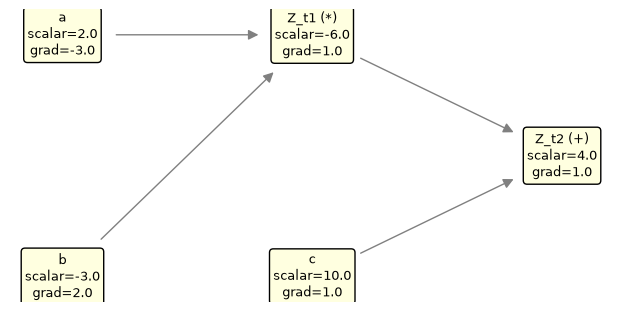

In [21]:
# With the following one-liner, you can visualize the comp. graph
draw_graph(Z_t2)

**Note:** `backward()` follows the provided template and does not clear existing gradients. Create a fresh graph for a new calculation. To reuse the same graph, first reset every node with `for n in trace_nodes(A): n.grad = 0.0`.

The sigmoid implementation uses two equivalent forms to avoid overflow for very negative inputs. The exponent-zero case is handled separately so that its derivative is zero even when the base is zero.

##### (b) **Task:** Build $\mathcal A$ from Task 2 with your engine, using one named node per intermediate variable from Task 2(a). Run the backward pass with the values from Task 2(d) and compare the results with your own computations. You can see it alse as a double-check of your own results.

Build the equation from Task 2 with your engine:
$$
\mathcal{A} = \sqrt{a + b + c^2} + \ln(a + b + c^2) + \frac{a + b + c^2}{bc^2}
$$
Create one named node per intermediate variable from Task 2(a), use the input values from Task 2(d), run `backward()` and compare all scalars and gradients with your hand computation.

**Note:** `x / y` is computed as `x * y**-1`, so your graph contains an extra unnamed `**-1` node.

**Answer:** The following code uses exactly the intermediate variables from Task 2(a). The expected values and gradients are taken from Task 2(d).

In [22]:
# * Task 3(b): build the graph, run backward and check the hand calculations.
a = Node(1.0, name='a')
b = Node(2.0, name='b')
c = Node(1.0, name='c')

t1 = c**2;       t1.name = 't1'
t2 = a + b;      t2.name = 't2'
t3 = t2 + t1;    t3.name = 't3'
t4 = t3.sqrt();  t4.name = 't4'
t5 = t3.log();   t5.name = 't5'
t6 = b * t1;     t6.name = 't6'
t7 = t3 / t6;    t7.name = 't7'
t8 = t4 + t5;    t8.name = 't8'
A = t8 + t7;     A.name = 'A'

A.backward()

results = [a, b, c, t1, t2, t3, t4, t5, t6, t7, t8, A]
expected_values = [1, 2, 1, 1, 3, 4, 2, np.log(4), 2, 2, 2 + np.log(4), 4 + np.log(4)]
expected_grads = [1, 0, -2, -1, 1, 1, 1, 1, -1, 1, 1, 1]

print(f"{'Node':<6} {'Value':>12} {'Hand value':>12} {'Gradient':>12} {'Hand grad':>12}")
for node, value, grad in zip(results, expected_values, expected_grads):
    print(f"{node.name:<6} {node.scalar:12.6f} {value:12.6f} {node.grad:12.6f} {grad:12.6f}")
    assert np.isclose(node.scalar, value)
    assert np.isclose(node.grad, grad)

# Check the extra reciprocal node introduced by division.
reciprocal = next(node for node in trace_nodes(A) if node._op == '**-1')
assert np.isclose(reciprocal.scalar, 0.5)
assert np.isclose(reciprocal.grad, 4.0)
print(f"{'**-1':<6} {reciprocal.scalar:12.6f} {0.5:12.6f} {reciprocal.grad:12.6f} {4.0:12.6f}")
print("All values and gradients match the hand computation.")

Node          Value   Hand value     Gradient    Hand grad
a          1.000000     1.000000     1.000000     1.000000
b          2.000000     2.000000     0.000000     0.000000
c          1.000000     1.000000    -2.000000    -2.000000
t1         1.000000     1.000000    -1.000000    -1.000000
t2         3.000000     3.000000     1.000000     1.000000
t3         4.000000     4.000000     1.000000     1.000000
t4         2.000000     2.000000     1.000000     1.000000
t5         1.386294     1.386294     1.000000     1.000000
t6         2.000000     2.000000    -1.000000    -1.000000
t7         2.000000     2.000000     1.000000     1.000000
t8         3.386294     3.386294     1.000000     1.000000
A          5.386294     5.386294     1.000000     1.000000
**-1       0.500000     0.500000     4.000000     4.000000
All values and gradients match the hand computation.


The comparison confirms:
$$
\boxed{\mathcal A=4+\ln4\approx5.386294,\qquad
\nabla_{(a,b,c)}\mathcal A=\begin{pmatrix}1\\0\\-2\end{pmatrix}.}
$$
For the extra reciprocal node $r=t_6^{-1}$, the value is $r=1/2$ and its gradient is $g_r=t_3=4$. It contributes $g_{t_6}=g_r(-t_6^{-2})=-1$, consistent with Task 2(d).

***Optional tip:*** You can check any gradient numerically with the finite difference $\frac{f(x+h) - f(x)}{h}$ for a small $h$, e.g. $h = 10^{-6}$. This is how a derivative is mathematically defined:
```python
f = lambda x: np.sqrt(x)
h = 1e-6
print((f(4.0 + h) - f(4.0)) / h)  # approx. 0.25 = 0.5 / sqrt(4)
```